# Tag 2 - Data Understanding

## SQLite-Daten auslesen
(siehe Modul 10.2)

In [2]:
import sqlite3
import pandas as pd

SQL_PATH = "../data/interim/projekt.sqlite"

con = sqlite3.connect(SQL_PATH)
tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type = 'table'", con)

print(tables['name'])
# -> 0    blockgruppen
#    Name: name, dtype: str

blockgroups = pd.read_sql("SELECT * FROM blockgruppen", con)

print(blockgroups.shape)
# -> (20640, 9)

0    blockgruppen
Name: name, dtype: str
(20640, 9)


## Wertebereiche prüfen
(für DATA_DICTIONARY)

In [3]:
print("---MedInc---")
print(blockgroups["MedInc"].max())
print(blockgroups["MedInc"].min())
print("---HouseAge---")
print(blockgroups["HouseAge"].max())
print(blockgroups["HouseAge"].min())
print("---AveRooms---")
print(blockgroups["AveRooms"].max())
print(blockgroups["AveRooms"].min())
print("---AveBedrms---")
print(blockgroups["AveBedrms"].max())
print(blockgroups["AveBedrms"].min())
print("---Population---")
print(blockgroups["Population"].max())
print(blockgroups["Population"].min())
print("---AveOccup---")
print(blockgroups["AveOccup"].max())
print(blockgroups["AveOccup"].min())
print("---Latitude---")
print(blockgroups["Latitude"].max())
print(blockgroups["Latitude"].min())
print("---Longitude---")
print(blockgroups["Longitude"].max())
print(blockgroups["Longitude"].min())
print("---MedHouseVal---")
print(blockgroups["MedHouseVal"].max())
print(blockgroups["MedHouseVal"].min())

---MedInc---
15.0001
0.4999
---HouseAge---
52.0
1.0
---AveRooms---
141.9090909090909
0.8461538461538461
---AveBedrms---
34.06666666666667
0.3333333333333333
---Population---
35682.0
3.0
---AveOccup---
1243.3333333333333
0.6923076923076923
---Latitude---
41.95
32.54
---Longitude---
-114.31
-124.35
---MedHouseVal---
5.00001
0.14999


## Auf Deckelungen prüfen

In [4]:
print("---MedInc---")
print(blockgroups["MedInc"].sort_values(ascending=False).head(50))
# print("---HouseAge---")
# print(blockgroups["HouseAge"].sort_values(ascending=False).head(1000))
# print("---AveRooms---")
# print(blockgroups["AveRooms"].sort_values(ascending=False).head(50))
# print("---AveBedrms---")
# print(blockgroups["AveBedrms"].sort_values(ascending=False).head(50))
# print("---Population---")
# print(blockgroups["Population"].sort_values(ascending=False).head(50))
# print("---AveOccup---")
# print(blockgroups["AveOccup"].sort_values(ascending=False).head(50))
# print("---Latitude---")
# print(blockgroups["Latitude"].sort_values(ascending=False).head(50))
# display("---Longitude---")
# print(blockgroups["Longitude"].sort_values(ascending=False).head(50))
# print("---MedHouseVal---")
# print(blockgroups["MedHouseVal"].sort_values(ascending=False).head(900))

---MedInc---
8851     15.0001
8850     15.0001
8849     15.0001
8848     15.0001
8852     15.0001
15241    15.0001
8878     15.0001
8805     15.0001
8847     15.0001
16910    15.0001
6590     15.0001
17108    15.0001
11520    15.0001
17118    15.0001
10673    15.0001
5291     15.0001
17111    15.0001
17110    15.0001
17107    15.0001
8846     15.0001
16171    15.0001
10760    15.0001
15693    15.0001
1566     15.0001
5248     15.0001
5247     15.0001
4626     15.0001
4678     15.0001
5242     15.0001
4605     15.0001
4352     15.0001
6592     15.0001
18501    15.0001
18504    15.0001
6399     15.0001
8854     15.0001
6391     15.0001
8853     15.0001
4606     15.0001
17858    15.0001
4604     15.0001
6736     15.0001
5257     15.0001
5275     15.0001
17170    15.0001
17166    15.0001
6591     15.0001
6727     15.0001
5281     15.0001
18052    15.0000
Name: MedInc, dtype: float64


## EDA

### Datentypen ermitteln

In [22]:
print(blockgroups.dtypes)

MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object


### Verteilung des Zielwerts

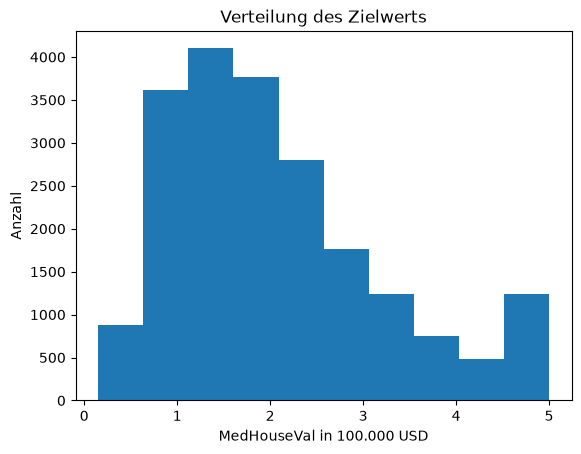

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

ax.hist(blockgroups["MedHouseVal"], bins=10)
ax.set_title("Verteilung des Zielwerts")
ax.set_xlabel("MedHouseVal in 100.000 USD")
ax.set_ylabel("Anzahl")

plt.show()

**Was sieht man?**
- eine mögliche Deckelung des Zielwerts bei 500.000 USD
- Die meisten Häuser haben einen Wert von ungefähr 100.000 - 200.000 USD

### Zusammenhang mit dem Einkommen


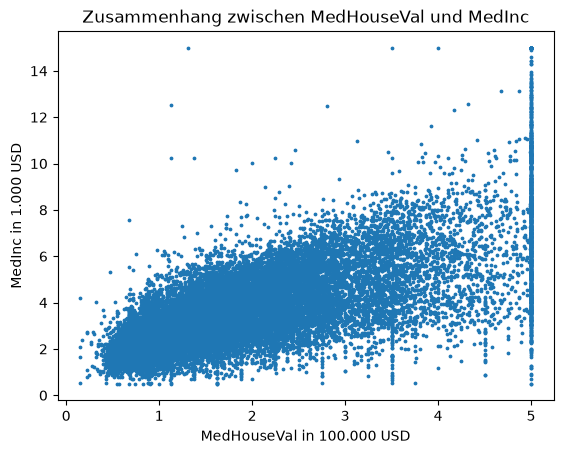

In [58]:
fig, ax = plt.subplots()

ax.scatter(blockgroups["MedHouseVal"], blockgroups["MedInc"], s=3)
ax.set_title("Zusammenhang zwischen MedHouseVal und MedInc")
ax.set_xlabel("MedHouseVal in 100.000 USD")
ax.set_ylabel("MedInc in 1.000 USD")

plt.show()

**Was sieht man?**
- eine fast bestätigte Deckelung des Zielwerts bei 500.000 USD
- Wenn das Median-Einkommen steigt, steigt im Normalfall auch der Median-Hauswert

### Räumliche Verteilung

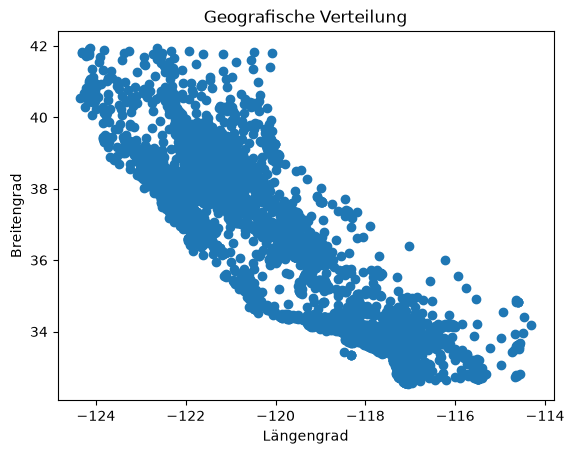

In [20]:
fig, ax = plt.subplots()

ax.scatter(blockgroups["Longitude"], blockgroups["Latitude"])
ax.set_title("Geografische Verteilung")
ax.set_xlabel("Längengrad")
ax.set_ylabel("Breitengrad")

plt.show()

**Was sieht man?**
- Man erkennt die geografische Form von Kalifornien
- Rund um Los Angeles (34, -118.15) und um San Francisco (37.5, -122) scheinen Ballungsräume zu sein.

### Fehlende Werte ermitteln

In [23]:
print(blockgroups.isna().sum())

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


### Duplikate ermitteln

In [54]:
print("Vollständige Duplikate:", blockgroups.duplicated().sum())

print("Duplikate in Latitude und Longitude:", 
      blockgroups.duplicated(subset=["Latitude", "Longitude"]).sum())

Vollständige Duplikate: 0
Duplikate in Latitude und Longitude: 8050


### Wertebereich ermitteln

In [28]:
blockgroups.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


### Ausreißer ermitteln

In [ ]:
columns = blockgroups.select_dtypes(include="number")
q1 = 0
q3 = 0
iqr = 0

# display(columns)
# print(columns.shape)
for column in columns:
    print(f"---{column}---")
    q1 = columns[column].quantile(0.25)
    q3 = columns[column].quantile(0.75)
    iqr = q3 - q1
    untergrenze = q1 - 1.5 * iqr
    obergrenze = q3 + 1.5 * iqr
    ausreisser = columns[(columns[column] < untergrenze) | (columns[column] > obergrenze)]

    print(f"Q1: {q1:.2f}")
    print(f"Q3: {q3:.2f}")
    print(f"Anzahl Ausreißer: {len(ausreisser)}")

---MedInc---
Q1: 2.56
Q3: 4.74
Anzahl Ausreißer: 681
---HouseAge---
Q1: 18.00
Q3: 37.00
Anzahl Ausreißer: 0
---AveRooms---
Q1: 4.44
Q3: 6.05
Anzahl Ausreißer: 511
---AveBedrms---
Q1: 1.01
Q3: 1.10
Anzahl Ausreißer: 1424
---Population---
Q1: 787.00
Q3: 1725.00
Anzahl Ausreißer: 1196
---AveOccup---
Q1: 2.43
Q3: 3.28
Anzahl Ausreißer: 711
---Latitude---
Q1: 33.93
Q3: 37.71
Anzahl Ausreißer: 0
---Longitude---
Q1: -121.80
Q3: -118.01
Anzahl Ausreißer: 0
---MedHouseVal---
Q1: 1.20
Q3: 2.65
Anzahl Ausreißer: 1071


## Ergebnis


### Datenqualität

| Spaltename | Fehlend | Duplikate | Wertebereich | Ausreißer |
| --- | --- | --- | --- | --- |
| `MedInc` | 0 | 0 | 0.4999 - 15.00 | 681 |
| `HouseAge` | 0 | 0 | 1.0 - 52.0 | 0 |
| `AveRooms` | 0 | 0 | 0.846 - 141.909 | 511 |
| `AveBedrms` | 0 | 0 | 0.333 - 34.067 | 1424 |
| `Population` | 0 | 0 | 3.0 - 35682.0 | 1196 |
| `AveOccup` | 0 | 0 | 0.692 - 1243.333 | 711 |
| `Latitude` | 0 | 0 | 32.54 - 41.95 | 0 |
| `Longitude` | 0 | 0 | -124.35 - -114.31 | 0 |
| `MedHouseVal` | 0 | 0 | 0.150 - 5.000 | 1071 |

### Befunde
| Befund | Auswirkung | Entscheidung |
| --- | --- | --- |
| Eine Deckelung in `MedHouseVal` bei 500.000 USD. | Höhere Median-Hauswerte können nicht berücksichtigt werden. | |
| Eine Deckelung in `HouseAge` bei 52.0 Jahren. | Höhere Hausalter können nicht berücksichtigt werden. | |
| Wenn das Median-Einkommen steigt, steigt im Normalfall auch der Median-Hauswert. | 
| Identische `Latitude` und `Longitude` Paare sind vorhanden | Könnte auf den gleichen Bezirk hinweisen | Vorerst als Rundungsfehler behandeln |
